In [1]:
import os
# setdefault: 그 키가 없을 때만 값을 넣는다. matplotlib 설정 폴더를 E: 캐시로 고정해 C:에 쓰지 않으려고 여기서 먼저 둔다.
os.environ.setdefault(r"MPLCONFIGDIR", r"E:\IT_SPACES\AI\.cache\matplotlib")
# setdefault: XDG 캐시 루트도 E:로 둔다. 뒤에 붙는 라이브러리가 사용자 홈 캐시를 만들지 않게 한다.
os.environ.setdefault(r"XDG_CACHE_HOME", r"E:\IT_SPACES\AI\.cache")
# setdefault: TEMP를 E:로 둔다. 임시 파일이 C: 사용자 폴더로 가지 않게 한다.
os.environ.setdefault(r"TEMP", r"E:\IT_SPACES\AI\.cache\tmp")
os.environ.setdefault(r"TMP", r"E:\IT_SPACES\AI\.cache\tmp")
try:
    import yfinance as yf
    # set_tz_cache_location: yfinance 시간대 sqlite 위치를 바꾼다. 기본 위치가 C:라서 E: 캐시로 옮긴다.
    yf.set_tz_cache_location(r"E:\IT_SPACES\AI\.cache\py-yfinance")
except Exception as e:
    # __name__: 예외 클래스 이름만 찍는다. 캐시 설정이 실패해도 노트북은 계속 가게 한다.
    print("yfinance tz cache skip:", type(e).__name__)


In [2]:
# Colab !pip skipped — packages live in SMA/.venv → ML/.venv
# Do not !pip here (C: cache risk).
print("yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted")


yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted


In [3]:
# Colab !pip skipped — packages live in SMA/.venv → ML/.venv
# Do not !pip here (C: cache risk).
print("yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted")


yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted


In [4]:
# IMPORTS
import numpy as np
import pandas as pd

#Fin Data Sources
import yfinance as yf
import pandas_datareader as pdr

#Data viz
import plotly.graph_objs as go
import plotly.graph_objects as go
import plotly.express as px

import time
from datetime import date

# for graphs
import matplotlib.pyplot as plt


# 0) Dataset for Modeling: Final Preparations

## 0.1) Importing data from Drive & defining variable sets
* automated version need to have a daily updated file/database entries

In [5]:
import gdown
from pathlib import Path

# Colab !gdown is a shell command, and /content/ is not a local path.
# Truncated Module 2 file: https://drive.google.com/file/d/1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5/view
file_id = "1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5"
# Path: 노트북 폴더 기준 파일 경로 객체를 만든다. 뒤에 exists/download가 같은 경로를 쓰게 한다.
data_path = Path("stocks_df_combined_2026_09_18.parquet.brotli")
# exists: 파일이 이미 있으면 True. 매번 Drive를 다시 받지 않으려고 먼저 확인한다.
if not data_path.exists():
    # download: Drive 파일을 로컬 경로로 받는다. Colab의 !gdown /content/ 는 Windows에서 안 된다.
    gdown.download(
        f"https://drive.google.com/uc?id={file_id}",
        str(data_path),
        quiet=False,
    )
# resolve: 상대 경로를 절대 경로로 푼다. stat().st_size: 바이트 크기. 받은 파일이 비지 않았는지 여기서 확인한다.
print(data_path.resolve(), data_path.stat().st_size)


E:\IT_SPACES\AI\ZoomCamp\SMA\03\modeling\stocks_df_combined_2026_09_18.parquet.brotli 143841500


In [6]:
# full dataset for 33 stocks
# read_parquet: parquet(brotli)를 DataFrame으로 읽는다. 이 수업의 33종목 일별 표가 이 파일에 있다.
df_full = pd.read_parquet(data_path)


In [7]:
# info: 행 수, 열 이름, 비어 있지 않은 칸 수, dtype을 찍는다. 읽은 직후 표가 기대만큼 큰지 본다.
df_full.info()


<class 'pandas.DataFrame'>
Index: 240759 entries, 0 to 6018
Columns: 203 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(129), int32(64), int64(5), str(2)
memory usage: 317.7 MB


In [8]:
# keys: 열 이름 Index를 돌려준다. 다음 칸에서 growth_/future 이름을 거르기 위해 전체 이름을 먼저 본다.
df_full.keys()


Index(['Open', 'High', 'Low', 'Close_x', 'Volume', 'Dividends', 'Stock Splits',
       'Ticker', 'Year', 'Month',
       ...
       'growth_brent_oil_7d', 'growth_brent_oil_30d', 'growth_brent_oil_90d',
       'growth_brent_oil_365d', 'growth_btc_usd_1d', 'growth_btc_usd_3d',
       'growth_btc_usd_7d', 'growth_btc_usd_30d', 'growth_btc_usd_90d',
       'growth_btc_usd_365d'],
      dtype='str', length=203)

In [9]:
# growth indicators (but not future growth)
# keys: 열 이름. find: 부분 문자열 위치, 없으면 -1. growth_로 시작하고 future가 없는 열만 남긴다. 미래 값은 피처로 쓰면 답이 새므로 뺀다.
GROWTH = [g for g in df_full.keys() if (g.find('growth_')==0)&(g.find('future')<0)]
GROWTH


['growth_1d',
 'growth_3d',
 'growth_7d',
 'growth_30d',
 'growth_90d',
 'growth_365d',
 'growth_dax_1d',
 'growth_dax_3d',
 'growth_dax_7d',
 'growth_dax_30d',
 'growth_dax_90d',
 'growth_dax_365d',
 'growth_snp500_1d',
 'growth_snp500_3d',
 'growth_snp500_7d',
 'growth_snp500_30d',
 'growth_snp500_90d',
 'growth_snp500_365d',
 'growth_dji_1d',
 'growth_dji_3d',
 'growth_dji_7d',
 'growth_dji_30d',
 'growth_dji_90d',
 'growth_dji_365d',
 'growth_epi_1d',
 'growth_epi_3d',
 'growth_epi_7d',
 'growth_epi_30d',
 'growth_epi_90d',
 'growth_epi_365d',
 'growth_gold_1d',
 'growth_gold_3d',
 'growth_gold_7d',
 'growth_gold_30d',
 'growth_gold_90d',
 'growth_gold_365d',
 'growth_wti_oil_1d',
 'growth_wti_oil_3d',
 'growth_wti_oil_7d',
 'growth_wti_oil_30d',
 'growth_wti_oil_90d',
 'growth_wti_oil_365d',
 'growth_brent_oil_1d',
 'growth_brent_oil_3d',
 'growth_brent_oil_7d',
 'growth_brent_oil_30d',
 'growth_brent_oil_90d',
 'growth_brent_oil_365d',
 'growth_btc_usd_1d',
 'growth_btc_usd_3d',


In [10]:
# leaving only Volume ==> generate ln(Volume)
OHLCV = ['Open','High','Low','Close','Adj Close_x','Volume']


In [11]:
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']


In [12]:
# keys/find: 이름에 future가 들어 있는 열만 고른다. 맞힐 목표 변수라 피처 목록과 분리한다.
TO_PREDICT = [g for g in df_full.keys() if (g.find('future')>=0)]
TO_PREDICT


['growth_future_30d', 'is_positive_growth_30d_future']

In [13]:
TO_DROP = ['Year','Date','index_x', 'index_y', 'index', 'Quarter','Adj Close_y'] + CATEGORICAL + OHLCV
TO_DROP


['Year',
 'Date',
 'index_x',
 'index_y',
 'index',
 'Quarter',
 'Adj Close_y',
 'Month',
 'Weekday',
 'Ticker',
 'ticker_type',
 'Open',
 'High',
 'Low',
 'Close',
 'Adj Close_x',
 'Volume']

In [14]:
# a small hack to avoid "divide by zero encountered in log"
# replace: Volume 0을 NaN으로 바꾼다. log(0)은 -inf라 모델 입력이 깨진다.
# fillna: 그 NaN을 1e-9로 채운다. 로그가 정의되는 아주 작은 양수가 필요하다.
# apply: 칸마다 np.log를 적용한다. 거래량 분포를 로그 스케일로 맞추려고 이 열을 만든다.
df_full['ln_volume'] = df_full.Volume.replace(0, np.nan).fillna(1e-9).apply(lambda x: np.log(x))


In [15]:
# manually defined features
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative','volatility', 'ln_volume']


In [16]:
# All Supported Ta-lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']


In [17]:
# keys/find: 이름이 cdl로 시작하는 캔들 패턴 열만 모은다. TA-Lib 패턴은 피처로 따로 센다.
TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl')>=0]
print(f'Technical patterns count = {len(TECHNICAL_PATTERNS)}, examples = {TECHNICAL_PATTERNS[0:5]}')


Technical patterns count = 61, examples = ['cdl2crows', 'cdl3blackrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside']


In [18]:
MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']


In [19]:
NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO


In [20]:
# CHECK: NO OTHER INDICATORS LEFT
# keys: 전체 열. 이미 분류한 이름에 없으면 OTHER로 남긴다. 빼먹은 피처가 있는지 확인하려고.
OTHER = [k for k in df_full.keys() if k not in OHLCV + CATEGORICAL + NUMERICAL + TO_DROP + TO_PREDICT]
OTHER


['Close_x', 'Dividends', 'Stock Splits', 'Close_y']

In [21]:
# nunique: Ticker의 서로 다른 값 개수. 33종목이 다 들어왔는지 센다.
df_full.Ticker.nunique()


33

In [22]:
# tickers, min-max date, count of daily observations
# groupby: Ticker별로 묶는다. 종목마다 기간이 다른지 보려면 묶어야 한다.
# agg: Date에 min, max, count를 한 번에 낸다. 시작일, 끝일, 관측 수를 종목별로 비교한다.
df_full.groupby(['Ticker'])['Date'].agg(['min','max','count'])


,min,max,count
Ticker,,,
AAPL,1980-12-12,2026-09-18,11534
ACN,2001-07-19,2026-09-18,6329
AMZN,1997-05-15,2026-09-18,7382
ASML,1995-03-15,2026-09-18,7931
AVGO,2009-08-06,2026-09-18,4306
BHARTIARTL.NS,2002-07-01,2026-09-18,6016
BRK-B,1996-05-09,2026-09-18,7639
CDI.PA,1992-01-27,2026-09-18,8933
GOOG,2004-08-19,2026-09-18,5556


In [23]:
# truncated df_full with 25 years of data (and defined growth variables)
# info: 2000년 이후로 자른 뒤 행 수와 dtype을 다시 본다. 잘린 표가 비지 않았는지 확인한다.
df = df_full[df_full.Date>='2000-01-01']
df.info()


<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 204 entries, Open to ln_volume
dtypes: datetime64[ns](3), float64(130), int32(64), int64(5), str(2)
memory usage: 268.6 MB


In [24]:
# let's look at the features count and df size:
# info: 숫자 피처만 골라 결측과 dtype을 본다. 모델에 넣을 열만 좁혀 검사한다.
df[NUMERICAL].info()


<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 184 entries, growth_1d to DGS10
dtypes: float64(121), int32(62), int64(1)
memory usage: 237.7 MB


## 0.2) [Code snippet 1] Generating dummies

In [25]:
# what are the categorical features?
CATEGORICAL


['Month', 'Weekday', 'Ticker', 'ticker_type']

In [26]:
# astype(str): Weekday를 문자열로 바꾼다. get_dummies가 범주 이름별로 열을 만들게 한다.
df['Weekday'] = df['Weekday'].astype(str)
# dt.month: datetime에서 월 숫자만 꺼낸다. astype(str): 그 숫자를 문자로 바꿔 더미 열 이름이 되게 한다.
df['Month'] = df['Month'].dt.month.astype(str) # Convert to string so get_dummies creates dummy columns properly


In [27]:
# Generate dummy variables (no need for bool, let's have int32 instead)
# get_dummies: 범주 값마다 0/1 열을 만든다. dtype int32는 트리가 bool 대신 정수를 받게 한다.
dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')


In [28]:
# TODO 1: define more categorical features, e.g. all combinations for <September+weekday>  (you'll see that September is actually an important dummy in one of the models)


In [29]:
# info: 더미 표의 열 수와 결측을 본다. 범주가 기대만큼 펼쳐졌는지 확인한다.
dummy_variables.info()


<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Data columns (total 55 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Month_1               202292 non-null  int32
 1   Month_10              202292 non-null  int32
 2   Month_11              202292 non-null  int32
 3   Month_12              202292 non-null  int32
 4   Month_2               202292 non-null  int32
 5   Month_3               202292 non-null  int32
 6   Month_4               202292 non-null  int32
 7   Month_5               202292 non-null  int32
 8   Month_6               202292 non-null  int32
 9   Month_7               202292 non-null  int32
 10  Month_8               202292 non-null  int32
 11  Month_9               202292 non-null  int32
 12  Weekday_0             202292 non-null  int32
 13  Weekday_1             202292 non-null  int32
 14  Weekday_2             202292 non-null  int32
 15  Weekday_3             202292 non-null  int32
 16 

In [30]:
# get dummies names in a list
# keys: 더미 열 이름. to_list: Index를 일반 리스트로 바꾼다. 나중에 NUMERICAL과 이어 붙이려고.
DUMMIES = dummy_variables.keys().to_list()


In [31]:
# Concatenate the dummy variables with the original DataFrame
# concat: 두 표를 가로(axis=1)로 붙인다. 원래 열과 더미를 한 표로 만들어야 모델 입력이 된다.
df_with_dummies = pd.concat([df, dummy_variables], axis=1)


In [32]:
# info: 숫자 피처+더미만 골라 결측과 행 수를 본다. 학습에 쓸 열 집합이 맞는지 확인한다.
df_with_dummies[NUMERICAL+DUMMIES].info()


<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 239 entries, growth_1d to ticker_type_US
dtypes: float64(121), int32(117), int64(1)
memory usage: 280.1 MB


## 0.3) [Code Snippet 2] Correlation analysis
* first approximation of "important" variables correlated with all variables we want to predict (TO_PREDICT)

In [33]:
TO_PREDICT


['growth_future_30d', 'is_positive_growth_30d_future']

In [34]:
# corr: 열끼리 피어슨 상관을 낸 뒤 목표 열 한 줄만 고른다. 30일 상승 여부와 같이 움직이는 피처를 찾으려고.
corr_is_positive_growth_30d_future = df_with_dummies[NUMERICAL+DUMMIES+TO_PREDICT].corr()['is_positive_growth_30d_future']


In [35]:
# create a dataframe for an easy way to sort
# DataFrame: Series를 한 열 표로 감싼다. 다음 칸 sort_values가 열 이름으로 정렬하게 한다.
corr_is_positive_growth_30d_future_df = pd.DataFrame(corr_is_positive_growth_30d_future)


In [36]:
# sort_values: 상관 오름차순. head(5): 맨 위 5행. 목표와 가장 반대로 움직이는 피처를 본다.
corr_is_positive_growth_30d_future_df.sort_values(by='is_positive_growth_30d_future').head(5)


,is_positive_growth_30d_future
DGS10,-0.071102
DGS5,-0.064277
growth_brent_oil_365d,-0.058880
gdppot_us_yoy,-0.049407
cpi_core_mom,-0.048873


In [37]:
# sort_values 뒤 tail(8): 상관이 가장 큰 8개. 목표와 같이 움직이는 피처를 본다.
corr_is_positive_growth_30d_future_df.sort_values(by='is_positive_growth_30d_future').tail(8)


,is_positive_growth_30d_future
Month_11,0.035443
Month_10,0.035999
growth_btc_usd_365d,0.037542
growth_future_30d,0.698218
is_positive_growth_30d_future,1.000000
cdl3starsinsouth,NaN
cdlconcealbabyswall,NaN
cdlmathold,NaN


In [38]:
# corr 뒤 한 열만 선택: 연속형 30일 미래 성장률과의 상관. 0/1 목표와 다른 관계를 보려고 따로 낸다.
corr_growth_future_30d = df_with_dummies[NUMERICAL+DUMMIES+TO_PREDICT].corr()['growth_future_30d']


In [39]:
corr_growth_future_30d_df = pd.DataFrame(corr_growth_future_30d)


In [40]:
corr_growth_future_30d_df.sort_values(by='growth_future_30d').head(5)


,growth_future_30d
growth_dji_365d,-0.078966
growth_brent_oil_365d,-0.075041
growth_dax_365d,-0.064342
growth_snp500_365d,-0.059060
growth_dji_30d,-0.058153


In [41]:
corr_growth_future_30d_df.sort_values(by='growth_future_30d').tail(8)


,growth_future_30d
Ticker_NVDA,0.053645
Month_10,0.053680
natr,0.055683
is_positive_growth_30d_future,0.698218
growth_future_30d,1.000000
cdl3starsinsouth,NaN
cdlconcealbabyswall,NaN
cdlmathold,NaN


## 0.4) [Code snippet 3] Temporal split of ~25 years of data (by date)

In [42]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    """
    Splits a DataFrame into three buckets based on the temporal order of the 'Date' column.

    Args:
        df (DataFrame): The DataFrame to split.
        min_date (str or Timestamp): Minimum date in the DataFrame.
        max_date (str or Timestamp): Maximum date in the DataFrame.
        train_prop (float): Proportion of data for training set (default: 0.6).
        val_prop (float): Proportion of data for validation set (default: 0.2).
        test_prop (float): Proportion of data for test set (default: 0.2).

    Returns:
        DataFrame: The input DataFrame with a new column 'split' indicating the split for each row.
    """
    # Timedelta: 일 수를 시간 간격으로 만든다. 전체 기간의 70%, 15% 지점을 날짜로 잘라 시간 순서를 지키려고.
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)

    split_labels = []
    for date in df['Date']:
        if date <= train_end:
            split_labels.append('train')
        elif date <= val_end:
            split_labels.append('validation')
        else:
            split_labels.append('test')

    df['split'] = split_labels
    return df


In [43]:
# min/max: Date의 가장 이른 날과 늦은 날. 비율 분할의 양 끝이 필요해서 먼저 구한다.
min_date_df = df_with_dummies.Date.min()
max_date_df = df_with_dummies.Date.max()

df_with_dummies = temporal_split(df_with_dummies,
                                 min_date = min_date_df,
                                 max_date = max_date_df)


In [44]:
# value_counts: split 값 개수. len으로 나누면 비율. 70/15/15에 가까운지 확인한다.
df_with_dummies['split'].value_counts()/len(df_with_dummies)


split
train         0.676458
test          0.163936
validation    0.159606
Name: count, dtype: float64

In [45]:
# remove the "segmentation" problem (warning message on df performance after many joins and data transformations)
# copy: 표를 새 메모리로 복제한다. 이어 붙인 표의 조각난 블록 경고를 없애려고 여기서 한 번 복사한다.
new_df = df_with_dummies.copy()


# 1) Modeling: "rule of thumb" or hand-predictions

In [46]:
# value_counts: Ticker별 행 수. 종목마다 일수가 비슷한지 본다.
new_df.Ticker.value_counts()


Ticker
MC.PA            6863
RMS.PA           6863
OR.PA            6863
CDI.PA           6863
SIE.DE           6826
MSFT             6718
AAPL             6718
NVDA             6718
AMZN             6718
BRK-B            6718
LLY              6718
JPM              6718
NVO              6718
ASML             6718
SAP              6718
TTE              6718
INFY             6718
HINDUNILVR.NS    6669
SBIN.NS          6667
RELIANCE.NS      6666
ITC.NS           6666
IBN              6659
ACN              6329
HDB              6328
LT.NS            6019
BHARTIARTL.NS    6016
TCS.NS           5987
GOOG             5556
V                4655
AVGO             4306
IDEXY            4192
META             3604
LICI.NS          1079
Name: count, dtype: int64

In [47]:
# let's have a time-series or one ticker
df_amzn = new_df[new_df.Ticker=='AMZN']


In [48]:
# px.line: Date-종가 선 그래프. AMZN 한 종목의 가격 흐름을 먼저 본다.
fig = px.line(df_amzn, x="Date", y="Close_x", title='AMZN daily close price')
# show: 브라우저에 그림을 연다.
fig.show()


In [49]:
# TRAIN / VALIDATION/ TEST split

# len: 행 개수. AMZN만 관측 수 비율로 자르려고 전체 길이를 센다. 이건 날짜 비율이 아니라 행 순서 분할이다.
total_length = len(df_amzn)
train_length = int(0.8 * total_length)
val_length = int(0.1 * total_length)

# iloc: 위치 번호로 행을 자른다. 시간 순으로 쌓인 표의 앞 80%를 학습으로 쓴다.
train_data = df_amzn.iloc[:train_length]
val_data = df_amzn.iloc[train_length:train_length+val_length]
test_data = df_amzn.iloc[train_length+val_length:]

fig = px.line(title='AMZN Close price daily for three time intervals Train/Validation/Test')
# add_scatter: 선 하나를 그림에 추가한다. 구간마다 색을 다르게 보려고 세 번 넣는다.
fig.add_scatter(x=train_data['Date'], y=train_data['Close_x'], mode='lines', name='Train', line=dict(color='blue'))
fig.add_scatter(x=val_data['Date'], y=val_data['Close_x'], mode='lines', name='Validation', line=dict(color='orange'))
fig.add_scatter(x=test_data['Date'], y=test_data['Close_x'], mode='lines', name='Test', line=dict(color='green'))

# update_layout: 제목 가로 위치를 0.5로 둔다. 제목을 가운데로 맞추려고.
fig.update_layout(title=dict(x=0.5))

fig.show()


In [50]:
# HIST ON NVDA DATA Train/Test/Validation
import plotly.graph_objects as go

fig = go.Figure()

# add_trace: 히스토그램 레이어를 하나 올린다. Histogram은 값의 분포를 막대로 센다. 구간별 30일 성장 분포를 겹쳐 비교한다.
fig.add_trace(go.Histogram(x=train_data['growth_future_30d'], name='Train', opacity=0.75))
fig.add_trace(go.Histogram(x=val_data['growth_future_30d'], name='Validation', opacity=0.75))
fig.add_trace(go.Histogram(x=test_data['growth_future_30d'], name='Test', opacity=0.75))

# update_layout: barmode overlay는 막대를 겹친다. 세 분포를 한 축에서 비교하려고.
fig.update_layout(barmode='overlay', title='Distribution of growth_future_30d for AMAZON (AMZN) Growth by Train/Valid/Test sets')
# update_traces: 이미 넣은 모든 트레이스의 투명도를 맞춘다.
fig.update_traces(opacity=0.75)

fig.show()


In [51]:
# HIST ON ALL DATA Train/Test/Validation
# comment: there are some outliers and hard co compare the distributions
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='train']['growth_future_30d'], name='Train', opacity=0.75))
fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='validation']['growth_future_30d'], name='Validation', opacity=0.75))
fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='test']['growth_future_30d'], name='Test', opacity=0.75))

fig.update_layout(barmode='overlay', title='Distribution of growth_future_30d for All tickers Growth by Train/Valid/Test sets')
fig.update_traces(opacity=0.75)

fig.show()


In [52]:
# px.histogram: 한 호출로 히스토그램을 만든다. color=split은 구간별 색, marginal=box는 위에 상자그림을 붙인다. 이상치를 같이 보려고.
fig = px.histogram(new_df,
                   x="growth_future_30d",
                   color="split",
                   marginal="box", # or violin, rug
                   )
                  #  hover_data=new_df.growth_future_5d)

fig.show()


In [53]:
# groupby: split별로 묶는다. describe: 개수, 평균, 분위수를 낸다. 구간마다 30일 성장 요약이 비슷한지 본다.
new_df.groupby(by='split')['growth_future_30d'].describe()


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,32173.0,1.024840,0.099602,0.588160,0.963423,1.018612,1.078930,1.648934
train,136842.0,1.023525,0.121019,0.246131,0.960703,1.020272,1.082224,5.179688
validation,32287.0,1.021737,0.106653,0.461847,0.960477,1.024186,1.084679,1.783609


In [54]:
# is_positive_growth_5d_future: ONLY AMZN stock

# value_counts(normalize=True): 비율. *100은 퍼센트. 0/1 비율을 막대 높이로 쓰려고.
train_counts = train_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100
val_counts = val_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100
test_counts = test_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100

fig = go.Figure()

# add_trace Bar: 막대 하나. text/textposition은 막대 안에 퍼센트를 적는다.
fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[0], val_counts[0], test_counts[0]], name='0',
                     text=[f'{count:.2f}%' for count in [train_counts[0], val_counts[0], test_counts[0]]], textposition='auto'))
fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[1], val_counts[1], test_counts[1]], name='1',
                     text=[f'{count:.2f}%' for count in [train_counts[1], val_counts[1], test_counts[1]]], textposition='auto'))

# update_layout barmode=stack: 0과 1 막대를 위로 쌓는다. 구간별 상승/하락 비율을 한 막대로 본다.
fig.update_layout(barmode='stack', title='Distribution of is_positive_growth_30d_future by Train/Validation/Test for AMZN stock')
fig.update_traces(opacity=0.75)

fig.show()


In [55]:
# ALL STOCKS: train/test/validation is more similar

train_counts = df_with_dummies[df_with_dummies.split=='train']['is_positive_growth_30d_future'].value_counts(normalize=True)*100
val_counts = df_with_dummies[df_with_dummies.split=='validation']['is_positive_growth_30d_future'].value_counts(normalize=True)*100
test_counts = df_with_dummies[df_with_dummies.split=='test']['is_positive_growth_30d_future'].value_counts(normalize=True)*100

fig = go.Figure()

fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[0], val_counts[0], test_counts[0]], name='0',
                     text=[f'{count:.2f}%' for count in [train_counts[0], val_counts[0], test_counts[0]]], textposition='auto'))
fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[1], val_counts[1], test_counts[1]], name='1',
                     text=[f'{count:.2f}%' for count in [train_counts[1], val_counts[1], test_counts[1]]], textposition='auto'))

fig.update_layout(barmode='stack', title='Distribution of is_positive_growth_30d_future by Train/Validation/Test for ALL stocks')
fig.update_traces(opacity=0.75)

fig.show()


# 1) Modeling: "rule of thumb" or hand-predictions

## 1.1) Review all the inputs again

In [56]:
# remove the "segmentation" problem (warning message on df performance after many joins and data transformations)
# copy: 조각난 블록을 한 덩어리로 다시 담는다. 이후 열 추가가 경고 없이 되게 한다.
new_df = df_with_dummies.copy()


In [57]:
# Full dataframe (transformed and truncated to 25 years)
new_df.info()


<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 260 entries, Open to split
dtypes: datetime64[ns](2), float64(130), int32(118), int64(5), str(5)
memory usage: 314.9 MB


In [58]:
# check one record: it has abs. values, text, and numbers
# head(1): 첫 1행만. 가격, 문자, 숫자가 한 행에 같이 있는지 본다.
new_df.head(1)


,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,split
3490,35.623602,36.00298,33.992277,35.377007,53228400.0,0.0,0.0,MSFT,2000,1,...,0,0,0,0,0,0,0,0,1,train


In [59]:
# time split on train/validation/test: FIXED dates of split, approx. 70%, 15%, 15% split
# groupby+agg: split마다 Date의 min, max, count. 구간이 시간으로 나뉘었는지 날짜로 확인한다.
new_df.groupby(['split'])['Date'].agg({'min','max','count'})


,min,max,count
split,,,
test,2022-09-16,2026-09-18,33163
train,2000-01-03,2018-09-13,136842
validation,2018-09-14,2022-09-15,32287


In [60]:
# what we try to predict
new_df[TO_PREDICT].head(1)


,growth_future_30d,is_positive_growth_30d_future
3490,0.845576,0


In [61]:
# to be used as features
new_df[NUMERICAL+DUMMIES].head(1)


,growth_1d,growth_3d,growth_7d,growth_30d,growth_90d,growth_365d,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,...,Ticker_RMS.PA,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US
3490,0.998394,0.988341,0.991494,1.372332,1.22295,2.063052,0.970196,0.983855,1.051736,1.134572,...,0,0,0,0,0,0,0,0,0,1


## 1.2) [Code Snippet 3] Manual "hand rule" predictions
* CCI (binary, on technical indicator CCI)
* growth_1d>1
* growth_1d>1 & growth_snp500_1d>1
*

In [62]:
# why does it work?
# compare a vector (pandas.core.series.Series) with scalar 200 ==> element_wise comparison with the number ==> generate a new DataFrame
# (only 5 values)
# DataFrame: 비교 결과 Series를 표로 감싼다. head: 앞 5행만. cci>200이 칸마다 True/False가 되는지 본다.
pd.DataFrame(new_df.cci>200).head()


,cci
3490,False
3491,False
3492,False
3493,False
3494,False


In [63]:
# generate manual predictions
# Let's label all prediction features with prefix "pred"
# astype(int): True/False를 1/0으로 바꾼다. 수동 규칙을 예측 열로 저장하려고.
new_df['pred0_manual_cci'] = (new_df.cci>200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d>1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)


In [64]:
# TODO 2: find more "hand rules" - can get it from decision trees important factors, or randomly build on other most popular macro/tech indicators/ manual_features


In [65]:
# sample(10): 임의 10행. 규칙 열과 실제 30일 상승이 한 행에서 어떻게 놓이는지 본다.
new_df[['cci','growth_30d','growth_snp500_30d','pred0_manual_cci','pred1_manual_prev_g1','pred2_manual_prev_g1_and_snp','is_positive_growth_30d_future']].sample(10)


,cci,growth_30d,growth_snp500_30d,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,is_positive_growth_30d_future
2649,103.089714,1.123681,1.053618,0,1,1,0
5864,-43.786227,0.821294,0.932105,0,0,0,0
2987,8.899969,1.078400,0.950505,0,1,0,1
2112,62.560176,1.040112,0.967243,0,1,0,1
8104,41.666279,1.012287,1.059284,0,1,1,0
3474,-204.776664,0.907936,0.993269,0,0,0,1
1398,-2.446265,1.160195,1.056724,0,1,1,0
5777,-22.326730,1.021359,0.913044,0,1,0,1
730,106.304854,1.399450,1.036343,0,1,1,0
5440,95.856957,1.055677,1.056435,0,1,1,0


In [66]:
# keys: 열 이름. startswith('pred'): 예측 열만. 정답 비교를 예측 열에만 적용하려고 모은다.
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS


['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp']

In [67]:
p = PREDICTIONS[0]
# split: '_'로 자른 리스트. [0]은 첫 조각. is_correct 열 이름에 pred0 같은 접두만 쓰려고.
part1 = p.split('_')[0] # first prefix before '_'
print(f'Full column name: {p}, only first part: {part1}')


Full column name: pred0_manual_cci, only first part: pred0


In [68]:
# One prediction: do we predict correctly?
new_df['is_correct_prediction'] = (new_df.pred0_manual_cci == new_df.is_positive_growth_30d_future)


In [69]:
new_df[['cci','pred0_manual_cci','is_positive_growth_30d_future','is_correct_prediction']]


,cci,pred0_manual_cci,is_positive_growth_30d_future,is_correct_prediction
3490,26.847016,0,0,True
3491,-34.317747,0,0,True
3492,-97.317306,0,0,True
3493,-169.948180,0,0,True
3494,-142.143966,0,0,True
...,...,...,...,...
6014,-107.444540,0,0,True
6015,-171.295854,0,0,True
6016,-211.714551,0,0,True
6017,-149.745765,0,0,True


In [70]:
# check "Precision" : the percentage of "correct" predictions , WHEN we predict "1" (POSITIVE future growth)
filter = (new_df.split=='test') & (new_df.pred0_manual_cci==1)
# value_counts: 맞음/틀림 개수. 테스트에서 1이라고 한 행만 남겨 정밀도를 세려고.
new_df[filter].is_correct_prediction.value_counts()


is_correct_prediction
True     520
False    401
Name: count, dtype: int64

In [71]:
# %% of correct predictions : 54%
# value_counts를 행 수로 나눈다. 1이라고 예측한 것 중 맞은 비율이다.
new_df[filter].is_correct_prediction.value_counts() / len(new_df[filter])


is_correct_prediction
True     0.564604
False    0.435396
Name: count, dtype: float64

In [72]:
# delete this column
del new_df["is_correct_prediction"]


In [73]:
# generate columns is_correct_
for pred in PREDICTIONS:
  # split: 열 이름 첫 조각. 예측마다 is_correct_pred0 같은 열을 만들려고.
  part1 = pred.split('_')[0] # first prefix before '_'
  # astype(int): 맞으면 1, 틀리면 0. 예측 열마다 정답 여부를 숫자로 남긴다.
  new_df[f'is_correct_{part1}'] =  (new_df[pred] == new_df.is_positive_growth_30d_future).astype(int)


In [74]:
# IS_CORRECT dataset
# startswith: is_correct_ 로 시작하는 열만. 정밀도 루프가 이 목록을 돈다.
IS_CORRECT =  [k for k in new_df.keys() if k.startswith('is_correct_')]
IS_CORRECT


['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2']

In [75]:
# sample of a dataframe
# sample(5): 임의 5행. 예측과 정답 열이 같이 있는지 본다.
new_df[PREDICTIONS+IS_CORRECT+['is_positive_growth_30d_future']].sample(5)


,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_positive_growth_30d_future
7909,0,0,0,0,0,0,1
12290,0,1,1,1,0,0,0
6737,0,1,0,0,1,0,1
10673,0,0,0,0,0,0,1
7104,0,1,1,0,1,1,1


In [76]:
# len: 테스트 행 수. 정밀도 분모가 될 크기를 확인한다.
len(new_df[new_df.split=='test'])


33163

In [77]:
# define "Precision" for ALL predictions on a Test dataset (~4 last years of trading)
# enumerate: 번호와 값을 같이 준다. IS_CORRECT[i]와 PREDICTIONS[i]를 짝지으려고.
for i,column in enumerate(IS_CORRECT):
  prediction_column = PREDICTIONS[i]
  is_correct_column = column
  filter = (new_df.split=='test') & (new_df[prediction_column]==1)
  print(f'Prediction column:{prediction_column} , is_correct_column: {is_correct_column}')
  # value_counts: 1이라고 한 테스트 행에서 맞은 개수와 틀린 개수.
  print(new_df[filter][is_correct_column].value_counts())
  print(new_df[filter][is_correct_column].value_counts()/len(new_df[filter]))

  print('---------')


Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    520
0    401
Name: count, dtype: int64
is_correct_pred0
1    0.564604
0    0.435396
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    11086
0     8072
Name: count, dtype: int64
is_correct_pred1
1    0.578662
0    0.421338
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
1    8728
0    6516
Name: count, dtype: int64
is_correct_pred2
1    0.572553
0    0.427447
Name: count, dtype: float64
---------


## 1.3) [Code Snippet 4 - Advanced] Statistical prediction : ARIMA models with 3 parameters (p,q,r)
* Finding best ARIMA params: not used in 2025

In [78]:
import pandas as pd

# copy: AMZN 표를 복제한다. set_index가 원본 new_df의 인덱스를 바꾸지 않게 한다.
df_arima = df_amzn.copy()

# set_index: Date를 행 인덱스로 올린다. inplace=True는 새 표를 안 만들고 그 표를 고친다. ARIMA는 날짜 순 시계열이 필요하다.
df_arima.set_index('Date', inplace=True)
# head: 앞 5행. 인덱스가 날짜로 바뀌었는지 본다.
df_arima.head()

# isin: 값이 목록에 있는지. 학습+검증 구간의 종가만 시계열로 쓴다. 다른 피처는 ARIMA에 넣지 않는다.
train_validation = df_arima[df_arima.split.isin(['train','validation'])]['Close_x']
test = df_arima[df_arima.split.isin(['test'])]['Close_x']

test_is_positive_future_30d = df_arima[df_arima.split.isin(['test'])]['is_positive_growth_30d_future']


In [79]:
# Colab !pip skipped — packages live in SMA/.venv → ML/.venv
# Do not !pip here (C: cache risk).
print("yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted")


yfinance/sklearn/etc. already in shared SMA .venv; !pip omitted


In [80]:
# Hyper parameters optimization
# # ~ several minutes to run
# # https://miqbalrp.medium.com/exploring-autoarima-in-python-for-multiple-time-series-forecasting-2f3004ba5a49
# # https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html
# # Auto ARIMA model fitting: iterating across params
# best_arima_model = auto_arima(train_validation,
#                    seasonal=False,
#                    trace=True,
#                    start_p=0, start_q=0, # minimum p and q
#                    max_p=12, max_q=12,   # maximum p and q
#                    D=None,               # let model determine 'D'
#                    )


In [81]:
# best model specification trained on train_validation
# # (p=6, q=2, r=2)
# get_params()['order']: 맞춰진 (p,d,q)를 꺼낸다. 이 칸은 주석이라 실행하지 않는다.
# best_arima_model.get_params()['order']

# summary: 계수표를 찍는다. 이것도 주석이다.
# best_arima_model.summary()


In [82]:
# len: 테스트 시계열 길이. 종목 하나에서 걸어야 할 예측 횟수를 센다.
len(test)


1005

In [83]:
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from math import sqrt


In [84]:
# [last day] this was used to train the model and obtain the "best" params
# [-1:]: 마지막 1행을 Series로 남긴다. 학습 구간의 마지막 종가를 확인한다.
train_validation[-1:]


Date
2022-09-15    126.279999
Name: Close_x, dtype: float64

In [85]:
# history as Series and the "last value" (current last known data)
history = [x for x in train_validation]
history[-1]


126.27999877929688

In [86]:
# [last day] now need to predict for each value of test, using all available history
test[-1:]


Date
2026-09-18    253.710007
Name: Close_x, dtype: float64

In [87]:
# slow to predict, can't quickly predict for ALL 33 tickers * 918 observationa (~30k predictions). Let's have only 1 ticker and these periods to predict:
# change this to 10 (1 min) or 50 (5min) to run faster

PERIODS_TO_PREDICT = 10  # ~2 minute to predict
# PERIODS_TO_PREDICT = 500  #VERY SLOW: used for slides


In [88]:
# staring to predict at day1 of test dataframe (we SEE the adj_close price and predict 5 periods ahead)
# head(5): 테스트 구간 첫 5일. 예측을 어디서 시작하는지 본다.
df_arima[df_arima.split=='test'].head(5)


,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,split
Date,,,,,,,,,,,,,,,,,,,,,
2022-09-16,122.779999,123.870003,120.699997,123.529999,115667800.0,0.0,0.0,AMZN,2022,9,...,0,0,0,0,0,0,0,0,1,test
2022-09-19,122.160004,124.709999,121.800003,124.660004,47279700.0,0.0,0.0,AMZN,2022,9,...,0,0,0,0,0,0,0,0,1,test
2022-09-20,123.349998,124.400002,121.139999,122.190002,47698400.0,0.0,0.0,AMZN,2022,9,...,0,0,0,0,0,0,0,0,1,test
2022-09-21,122.489998,123.760002,118.449997,118.540001,58498900.0,0.0,0.0,AMZN,2022,9,...,0,0,0,0,0,0,0,0,1,test
2022-09-22,117.080002,118.790001,116.260002,117.309998,55229200.0,0.0,0.0,AMZN,2022,9,...,0,0,0,0,0,0,0,0,1,test


In [89]:
# 2026: static params, instead of autotuned

# p,q,r = best_arima_model.get_params()['order']
p,q,r = 6,2,2


In [106]:
%%time
import numpy as np

# rolling forecast for ARIMA(6,2,2) model
# https://machinelearningmastery.com/arima-for-time-series-forecasting-with-python/


history = [x for x in train_validation]
predictions = []
decisions = []
is_correct_decisions = []

tp=0 # true positive
fp=0 # false positive

for t in range(PERIODS_TO_PREDICT):
  # iloc: 위치 t의 값 하나. 그 날 종가와, 그 날 기준 30일 뒤 상승 여부 정답을 꺼낸다.
  current_adj_close = test.iloc[t] # current adj_close price when we do the prediction
  current_is_future_growth_30d = test_is_positive_future_30d.iloc[t]

  # ARIMA: (p,d,q) 모델을 지금까지의 history에 만든다. 매 걸음 다시 맞추는 walk-forward다.
  model = ARIMA(history, order = (p,q,r)) # substitute best parameters AND RETRAIN the model (very expensive)
  # fit: 계수를 추정한다.
  model_fit = model.fit()
  # forecast(steps=30): 앞으로 30걸음의 예측 배열. 30거래일 앞 가격이 필요해서 30으로 둔다.
  output = model_fit.forecast(steps=30) # forecast for 30 periods ahead

  yhat = output[29] # prediction 30 periods ahead

  if yhat > current_adj_close:
    prediction = 1
  else:
    prediction = 0

  # astype(int): True/False를 1/0으로. 예측과 실제 상승 여부가 같은지 숫자로 남긴다.
  is_correct = (prediction==current_is_future_growth_30d).astype(int)

  if prediction == 1:
    if is_correct ==1:
      tp+=1
    else:
      fp+=1

  predictions.append(yhat)

  decisions.append(prediction)
  is_correct_decisions.append(is_correct)
  # append: 오늘 실제 종가를 역사에 넣는다. 다음 걸음은 이 값을 알고 예측한다.
  history.append(current_adj_close)
  actual_30d_ahead = test.iloc[t + 29] if (t + 29) < len(test) else np.nan
  # round: 소수 1자리. 로그가 읽히게 가격만 줄인다.
  print(f'step {t}, current_price = {np.round(current_adj_close,1)}, predicted_30d_ahead={np.round(yhat,1)}, actual_30d_ahead={np.round(actual_30d_ahead,1)}, decision = {prediction}, is_correct = {is_correct} ')


step 0, current_price = 123.5, predicted_30d_ahead=127.5, actual_30d_ahead=111.0, decision = 1, is_correct = 0 
step 1, current_price = 124.7, predicted_30d_ahead=124.3, actual_30d_ahead=103.4, decision = 0, is_correct = 1 
step 2, current_price = 122.2, predicted_30d_ahead=125.7, actual_30d_ahead=102.4, decision = 1, is_correct = 0 
step 3, current_price = 118.5, predicted_30d_ahead=123.2, actual_30d_ahead=96.8, decision = 1, is_correct = 0 
step 4, current_price = 117.3, predicted_30d_ahead=119.4, actual_30d_ahead=92.1, decision = 1, is_correct = 0 
step 5, current_price = 113.8, predicted_30d_ahead=118.4, actual_30d_ahead=89.3, decision = 1, is_correct = 0 
step 6, current_price = 115.2, predicted_30d_ahead=114.7, actual_30d_ahead=91.0, decision = 0, is_correct = 1 
step 7, current_price = 114.4, predicted_30d_ahead=116.0, actual_30d_ahead=90.5, decision = 1, is_correct = 0 
step 8, current_price = 118.0, predicted_30d_ahead=115.2, actual_30d_ahead=90.0, decision = 0, is_correct = 1

In [107]:
tp


0

In [108]:
fp


7

In [109]:
precision = tp / (tp+fp)
precision


0.0

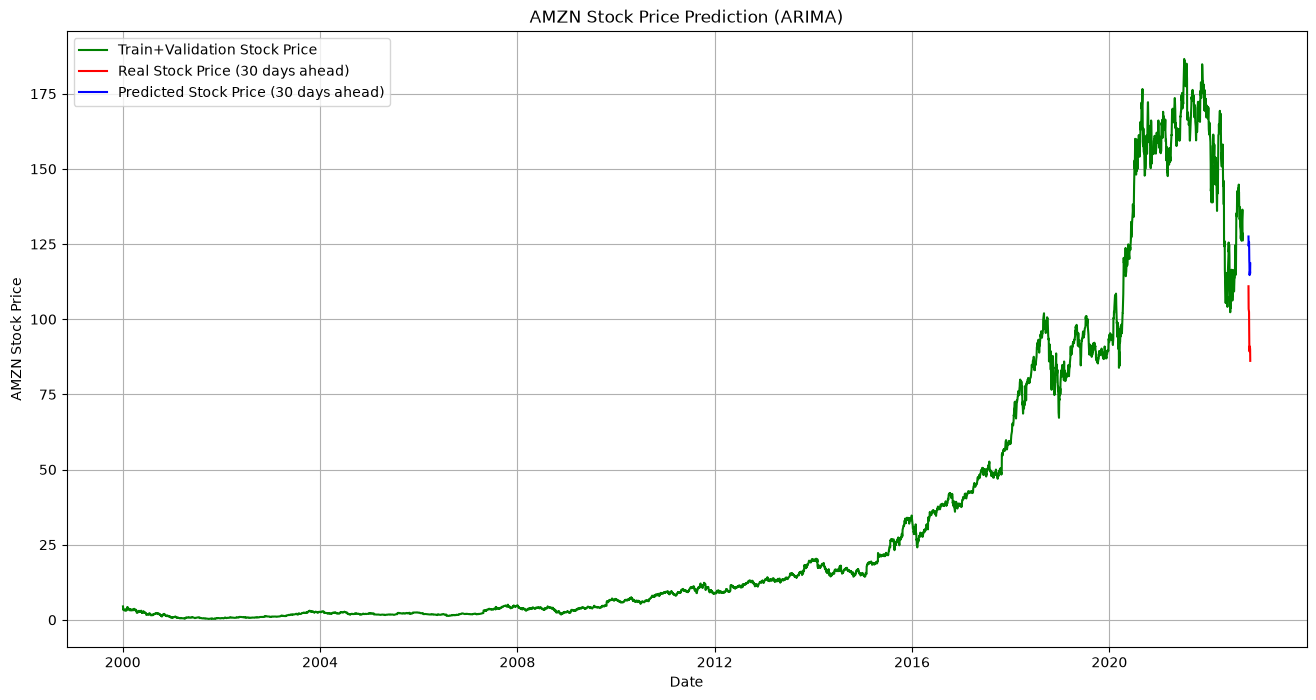

In [110]:
import matplotlib.pyplot as plt

# figure: 그림 크기를 인치로 연다. 긴 시계열을 가로로 넓게 보려고 (16, 8).
plt.figure(figsize=(16,8))

# plot: x, y 선을 그린다. 학습+검증 종가를 초록으로 깐다.
plt.plot(train_validation.index, train_validation, color='green', label = 'Train+Validation Stock Price')

start_idx_for_plot = 29
end_idx_for_plot = PERIODS_TO_PREDICT + 29

if end_idx_for_plot <= len(test):
    actual_forecast_dates = test.index[start_idx_for_plot : end_idx_for_plot]
    # iloc: 30일 뒤부터의 실제 가격 조각. 예측 yhat이 가리키는 날짜와 맞추려고 29부터 자른다.
    actual_forecast_values = test.iloc[start_idx_for_plot : end_idx_for_plot]

    plt.plot(actual_forecast_dates, actual_forecast_values, color = 'red', label = 'Real Stock Price (30 days ahead)')
    plt.plot(actual_forecast_dates, predictions, color = 'blue', label = 'Predicted Stock Price (30 days ahead)')
else:
    print(f"Not enough data in 'test' for {PERIODS_TO_PREDICT} 30-day ahead predictions to align for plotting.")
    print(f"'test' length: {len(test)}, required length for plotting {end_idx_for_plot}")

plt.title('AMZN Stock Price Prediction (ARIMA)')
plt.xlabel('Date')
plt.ylabel('AMZN Stock Price')
# legend: 색 설명을 켠다. grid: 격자. show: 창에 그린다.
plt.legend()
plt.grid(True)
plt.show()


## 1.4) [Code Snippet 5] Binary Decision Tree

In [111]:
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score


### 1.4.1) Define dataframes AND perform data cleaning
* define X_train (dataframe), X_test (dataframe), y_train (series), y_test (series)
* replace +-inf. with 0
* fill NaNs with 0 (you can drop it too, but will loose a lot of data in our case
* remove 1-2% outliers (in each dimension, or only in variable to_predict :: we won't use it for a Decision Tree

In [112]:
# Decision Tree doesn't like too large and inf. values
import numpy as np

def remove_infinite_values(X):
    """
    Remove infinite values from the input array.

    Parameters:
    - X: Input array (NumPy array or array-like)

    Returns:
    - Array with infinite values removed
    """
    # isfinite: 유한한 칸만 True. all(axis=1): 그 행의 모든 칸이 유한한지. 무한 값이 있는 행을 통째로 버리려고.
    return X[np.isfinite(X).all(axis=1)]

# Example usage:
# Assuming X is your input data
# filtered_X = remove_infinite_values(X)


In [113]:
# look carefully for 'count' to be close to total values (or you need to replace NaNs/remove NaNs), and min/max doesn't equal to -+inf.
#  it will give you an idea to dig deeper into some features to understand the 'nature' of a problem
# set_option: describe 출력 행 제한을 푼다. 피처가 많아서 중간이 ... 로 잘리지 않게 한다.
pd.set_option('display.max_rows', None)

# describe: 개수, 평균, 최소, 최대, 분위수. T: 행/열을 바꾼다. 피처가 행으로 오게 해 한 피처씩 읽는다.
new_df[NUMERICAL+DUMMIES].describe().T


,count,mean,std,min,25%,50%,75%,max
growth_1d,202277.0,1.000825e+00,2.418083e-02,2.300551e-01,9.906975e-01,1.000448e+00,1.010598e+00,4.374775e+00
growth_3d,202247.0,1.002419e+00,3.950841e-02,2.425170e-01,9.841664e-01,1.002000e+00,1.019992e+00,4.446675e+00
growth_7d,202187.0,1.005547e+00,5.793361e-02,2.326554e-01,9.771211e-01,1.005036e+00,1.033039e+00,4.599881e+00
growth_30d,201842.0,1.023700e+00,1.160659e-01,2.461313e-01,9.611859e-01,1.020682e+00,1.082346e+00,5.179688e+00
growth_90d,200942.0,1.073406e+00,2.146786e-01,1.890117e-01,9.546445e-01,1.058288e+00,1.171195e+00,5.970047e+00
growth_365d,196532.0,1.344875e+00,6.061920e-01,9.783037e-02,1.012544e+00,1.237688e+00,1.524308e+00,9.819908e+00
growth_dax_1d,198978.0,1.000282e+00,1.385765e-02,8.776139e-01,9.939737e-01,1.000718e+00,1.007083e+00,1.114020e+00
growth_dax_3d,198978.0,1.000900e+00,2.359598e-02,8.374862e-01,9.895442e-01,1.002065e+00,1.013663e+00,1.144124e+00
growth_dax_7d,198978.0,1.002217e+00,3.506705e-02,7.318924e-01,9.851298e-01,1.004732e+00,1.021454e+00,1.232460e+00
growth_dax_30d,198978.0,1.009657e+00,6.979685e-02,6.263172e-01,9.756793e-01,1.015180e+00,1.049860e+00,1.288371e+00


In [114]:
# Split the data into training and testing sets based on the split date
features_list = NUMERICAL+DUMMIES
to_predict = 'is_positive_growth_30d_future'

# isin: split이 목록에 있는 행. copy(deep=True): 깊은 복사. 이후 결측 채우기가 new_df를 건드리지 않게 한다.
train_df = new_df[new_df.split.isin(['train','validation'])].copy(deep=True)
test_df = new_df[new_df.split.isin(['test'])].copy(deep=True)

# need Date and Ticker later when merging predictions to the dataset
X_train = train_df[features_list+[to_predict,'Date','Ticker']]
X_test = test_df[features_list+[to_predict,'Date','Ticker']]

# shape: (행, 열). 학습과 테스트 크기를 비교한다.
print(f'length: X_train {X_train.shape},  X_test {X_test.shape}')


length: X_train (169129, 242),  X_test (33163, 242)


In [115]:
# Can't have +-inf values . E.g. ln(volume)=-inf when volume==0 => substitute with 0

# chained_assignment = None: SettingWithCopy 경고를 끈다. 바로 아래 inplace 대입이 뷰 경고를 내기 때문이다.
pd.options.mode.chained_assignment = None  # default='warn'

# replace: +inf, -inf를 NaN으로 바꾼다. 트리는 무한 값을 못 받는다.
X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# fillna(0): NaN을 0으로 채운다. 행을 버리지 않고 트리가 학습하게 하려고 0을 넣는다.
X_train.fillna(0, inplace=True)
X_test.fillna(0, inplace=True)

print(f'length: X_train_imputed {X_train.shape},  X_test_imputed {X_test.shape}')


length: X_train_imputed (169129, 242),  X_test_imputed (33163, 242)


In [116]:
# you may want to remove 1-2% outliers based on percentile ==> not used here in Decision Trees
def remove_outliers_percentile(X, lower_percentile=1, upper_percentile=99):
    """
    Remove outliers from the input array based on percentiles.

    Parameters:
    - X: Input array (NumPy array or array-like)
    - lower_percentile: Lower percentile threshold (float, default=1)
    - upper_percentile: Upper percentile threshold (float, default=99)

    Returns:
    - Array with outliers removed
    """
    # percentile: 열마다 1%, 99% 경계. axis=0은 열 방향. 극단값을 자를 경계를 만든다.
    lower_bound = np.percentile(X, lower_percentile, axis=0)
    upper_bound = np.percentile(X, upper_percentile, axis=0)
    # logical_and + all: 모든 열이 경계 안인 행만 True. 한 열이라도 벗어나면 그 행을 버린다.
    mask = np.logical_and(np.all(X >= lower_bound, axis=1), np.all(X <= upper_bound, axis=1))
    return X[mask]

# Example usage:
# Assuming X is your input data
# filtered_X = remove_outliers_percentile(X, lower_percentile=1, upper_percentile=99)


In [117]:
X_train_imputed = X_train # we won't use outliers removal to save more data to train: remove_outliers_percentile(X_train)
X_test_imputed = X_test # we won't use outliers removal to save more data to test: remove_outliers_percentile(X_test)


In [118]:
# same shape
print(f'length: X_train_imputed {X_train_imputed.shape},  X_test_imputed {X_test_imputed.shape}')


length: X_train_imputed (169129, 242),  X_test_imputed (33163, 242)


In [119]:
y_train = X_train_imputed[to_predict]
y_test = X_test_imputed[to_predict]

# del: 목표 열을 피처 표에서 지운다. 답이 피처로 들어가면 트리가 답을 외운다.
del X_train_imputed[to_predict]
del X_test_imputed[to_predict]


### 1.4.2 Estimation of a Decision Tree model

In [120]:
# INPUTS:
# X_train_imputed : CLEAN dataFrame with only numerical features (train+validation periods)
# X_test_imputed : CLEAN dataFrame with only numerical features (test periods)

# y_train : true values for the train period
# y_test  : true values for the test period


In [121]:
# estimation/fit function (using dataframe of features X and what to predict y) --> optimising total accuracy
# max_depth is hyperParameter
def fit_decision_tree(X, y, max_depth=20):
  # DecisionTreeClassifier: 분류 나무. max_depth는 질문 깊이 제한. 너무 깊으면 학습 구간에 과적합된다.
  clf = DecisionTreeClassifier(max_depth=max_depth)

  # fit: X로 y를 맞춘다. 여기서 분할 규칙이 정해진다.
  clf.fit(X, y)
  # columns: 피처 이름. 나중에 중요도, 나무 그림의 feature_names로 쓴다.
  return clf, X.columns


In [122]:
%%time
# drop: Date, Ticker 열을 뺀 표. axis=1은 열 방향. 나무는 날짜 문자열을 피처로 쓰면 안 되고, 나중에 합칠 때 원본에는 남겨 둔다.
clf_20, train_columns = fit_decision_tree(X=X_train_imputed.drop(['Date','Ticker'],axis=1),
                           y=y_train,
                           max_depth=20)


CPU times: total: 1min 7s
Wall time: 1min 13s


In [123]:
%%time
clf_10, train_columns = fit_decision_tree(X=X_train_imputed.drop(['Date','Ticker'],axis=1),
                           y=y_train,
                           max_depth=10)


CPU times: total: 39.6 s
Wall time: 42.8 s


In [124]:
# TODO 3: TRAIN only on train dataset, experiment with trees with depth 1..20 --> find the best one on VALID dataset
#       for the "best" tree model: find precision on the TEST set


### 1.4.3 Inference for a Decision Tree

In [125]:
def predict_decision_tree(clf:DecisionTreeClassifier, df_X:pd.DataFrame, y_true: pd.Series):
  # predict: 학습된 규칙으로 0/1을 낸다. 테스트 피처에 대해 상승 여부를 예측한다.
  y_pred = clf.predict(df_X)

  # tree_.max_depth: 실제로 자란 깊이. 지정한 max_depth와 비교하려고 찍는다.
  max_depth = clf.tree_.max_depth
  print("Maximum depth of the decision tree:", max_depth)

  # accuracy_score: 전체 중 맞은 비율. precision_score: 1이라고 한 것 중 맞은 비율.
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  print(f'Accuracy ={accuracy}, precision = {precision}')

  # concat axis=1: 피처, 정답, 예측을 가로로 붙인다. Series는 같은 인덱스를 써야 행이 맞는다.
  result_df = pd.concat([df_X, y_true, pd.Series(y_pred, index=df_X.index, name='pred_')], axis=1)

  return result_df


In [126]:
# drop axis=1: 테스트에서도 Date, Ticker를 빼고 예측한다. 학습 때 뺀 열과 같아야 나무가 받는다.
pred20 = predict_decision_tree(clf_20, X_test_imputed.drop(['Date','Ticker'],axis=1), y_test)


Maximum depth of the decision tree: 20
Accuracy =0.4776105901154902, precision = 0.5765879163439195


In [127]:
# Predictions of a decision tree of depth "20"
# value_counts: pred_의 0/1 개수. 깊이 20이 1을 얼마나 찍는지 본다.
pred20.pred_.value_counts()


pred_
0    22835
1    10328
Name: count, dtype: int64

In [128]:
pred10 = predict_decision_tree(clf_10, X_test_imputed.drop(['Date','Ticker'],axis=1), y_test)


Maximum depth of the decision tree: 10
Accuracy =0.487169435817025, precision = 0.5980787108769755


In [129]:
# tail: 마지막 5행. 예측 표 끝을 본다.
pred10.tail()


,growth_1d,growth_3d,growth_7d,growth_30d,growth_90d,growth_365d,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,...,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,is_positive_growth_30d_future,pred_
6014,1.000000,1.002065,0.988855,0.976571,1.007333,1.144080,0.995004,0.994697,0.978368,0.978443,...,0,0,0,0,0,0,1,0,0,0
6015,0.979647,0.973628,0.971393,0.965088,1.008249,1.123779,0.998485,1.001622,0.975270,0.969466,...,0,0,0,0,0,0,1,0,0,0
6016,0.988833,0.968708,0.952163,0.938551,0.981892,1.129175,1.005333,0.998795,0.981975,0.977473,...,0,0,0,0,0,0,1,0,0,0
6017,1.007485,0.975958,0.972150,0.944458,0.983065,1.143249,1.007008,1.010845,0.988814,0.983802,...,0,0,0,0,0,0,1,0,0,0
6018,1.012721,1.008907,0.990414,0.957840,1.003568,1.157707,0.983954,0.996133,0.989350,0.961421,...,0,0,0,0,0,0,1,0,0,0


In [130]:
import numpy as np
import pandas as pd

# globals().get: 노트북 변수 사전에서 꺼낸다. 없으면 빈 리스트. 앞 셀을 건너뛰어도 이름만 있게 한다.
global_NUMERICAL = globals().get('NUMERICAL', [])
global_DUMMIES = globals().get('DUMMIES', [])
global_TO_PREDICT = globals().get('TO_PREDICT', [])

features_list_from_globals = global_NUMERICAL + global_DUMMIES
# 미래 성장 열은 TO_PREDICT의 두 번째 이름이다. 목록이 비면 기본 열 이름을 쓴다.
to_predict_col = global_TO_PREDICT[1] if len(global_TO_PREDICT) > 1 else 'is_positive_growth_30d_future'

# empty: 행이 하나도 없는지. 빈 표면 테스트 표를 다시 만들 수 없다.
if 'new_df' not in globals() or globals()['new_df'].empty:
    raise RuntimeError("new_df is not defined or is empty. Please run all preceding data loading and preprocessing cells.")

# isin: split이 test인 행. copy(deep=True): 깊은 복사. 결측 채우기가 new_df를 바꾸지 않게 한다.
test_df = new_df[new_df.split.isin(['test'])].copy(deep=True)

# 전역 피처 이름 중 이 표에 실제로 있는 열만. 없는 이름을 고르면 KeyError가 난다.
valid_features = [col for col in features_list_from_globals if col in test_df.columns]

X_test_columns_to_select = valid_features + ['Date', 'Ticker']
if to_predict_col in test_df.columns and to_predict_col not in X_test_columns_to_select:
    X_test_columns_to_select.append(to_predict_col)

# copy: 선택 열만 새 표. 뷰가 아니어서 아래 inplace 대입이 안전하다.
X_test = test_df[X_test_columns_to_select].copy()

# chained_assignment None: SettingWithCopy 경고를 끈다. replace/fillna inplace가 경고를 내기 때문이다.
pd.options.mode.chained_assignment = None
# replace: 무한대를 NaN으로 바꾼다. 트리는 inf를 받지 못한다.
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
# fillna(0): 그 NaN을 0으로 채운다. 행을 버리지 않고 예측에 쓰려고.
X_test.fillna(0, inplace=True)
pd.options.mode.chained_assignment = 'warn'

X_test_imputed = X_test.copy()

# 목표 열이 피처에 남아 있으면 지운다. 답이 입력으로 들어가면 안 된다.
if to_predict_col in X_test_imputed.columns:
    del X_test_imputed[to_predict_col]

# shape: (행, 열). 다시 만든 테스트 입력 크기를 확인한다.
print(f'X_test_imputed has been recreated with shape: {X_test_imputed.shape}')


X_test_imputed has been recreated with shape: (33163, 241)


In [131]:
# join: 인덱스가 같은 열을 붙인다. head: 앞 5행. Date가 없는 pred10에 키를 붙일 수 있는지 먼저 본다.
X_test_imputed.join(pred10['pred_']).head()


,growth_1d,growth_3d,growth_7d,growth_30d,growth_90d,growth_365d,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,...,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,Date,Ticker,pred_
9203,0.997392,0.971229,0.948274,0.864655,0.929136,0.991729,0.983375,0.966056,0.986473,0.938657,...,0,0,0,0,0,0,1,2022-09-16,MSFT,0
9204,0.999101,0.969471,0.945846,0.866138,0.911353,0.977731,1.004865,0.982748,0.992167,0.935384,...,0,0,0,0,0,0,1,2022-09-19,MSFT,1
9205,0.991534,0.988059,0.916774,0.866740,0.934679,0.959602,0.989658,0.977940,0.968110,0.936155,...,0,0,0,0,0,0,1,2022-09-20,MSFT,1
9206,0.985564,0.976342,0.896118,0.848237,0.939945,0.945527,1.007602,1.002032,0.952611,0.931846,...,0,0,0,0,0,0,1,2022-09-21,MSFT,0
9207,1.008496,0.985523,0.956308,0.835148,0.926984,0.944042,0.981553,0.978786,0.950161,0.915084,...,0,0,0,0,0,0,1,2022-09-22,MSFT,1


In [132]:
# pred10/pred20는 Date, Ticker를 뺀 표로 만들었다. join은 같은 인덱스에 키를 다시 붙인다.
date_ticker_info = X_test_imputed[['Date', 'Ticker']]

# join: 인덱스 기준으로 열을 붙인다. 예측 행과 날짜/종목 행을 맞추려고.
pred10_with_date_ticker = pred10.join(date_ticker_info)
pred20_with_date_ticker = pred20.join(date_ticker_info)

# copy: 열 두 개만 새 표로. 원본 예측 표를 슬라이스 경고 없이 고치려고.
pred10_df = pred10_with_date_ticker[['Date', 'Ticker']].copy()
# values: 위치를 유지한 배열. 인덱스가 어긋난 채 대입되지 않게 값만 넣는다.
pred10_df['pred_tree_clf10'] = pred10_with_date_ticker['pred_'].values

pred20_df = pred20_with_date_ticker[['Date', 'Ticker']].copy()
pred20_df['pred_tree_clf20'] = pred20_with_date_ticker['pred_'].values

# copy: 테스트 행만 복제. 합치기 전에 new_df 전체를 건드리지 않으려고.
new_df_test_subset = new_df[new_df['split'] == 'test'].copy()

# merge: Date, Ticker가 같은 행에 예측 열을 붙인다. how='left'는 왼쪽 테스트 행을 모두 남긴다.
merged_df = pd.merge(new_df_test_subset, pred10_df[['Date', 'Ticker', 'pred_tree_clf10']],
                     on=['Date', 'Ticker'], how='left')

merged_df = pd.merge(merged_df, pred20_df[['Date', 'Ticker', 'pred_tree_clf20']],
                     on=['Date', 'Ticker'], how='left')

# copy: 원본을 그대로 두고 갱신용 표를 만든다.
new_df_copy = new_df.copy()
# set_index drop=False: Date, Ticker를 인덱스로 올리되 열로도 남긴다. loc로 테스트 행만 집으려고.
new_df_indexed = new_df_copy.set_index(['Date', 'Ticker'], drop=False)
merged_df_indexed = merged_df.set_index(['Date', 'Ticker'], drop=False)

# loc: 그 인덱스 행의 두 열에 값을 넣는다. 테스트 행만 예측을 채우려고.
new_df_indexed.loc[merged_df_indexed.index, ['pred_tree_clf10', 'pred_tree_clf20']] = \
    merged_df_indexed[['pred_tree_clf10', 'pred_tree_clf20']]

# reset_index(drop=True): 인덱스를 0,1,2...로 되돌리고 인덱스 이름은 열로 중복 추가하지 않는다.
new_df = new_df_indexed.reset_index(drop=True)

print("Decision tree predictions merged into new_df.")
# tail: 마지막 5행. 예측 열이 붙었는지 본다.
print(new_df[['Date', 'Ticker', 'pred_tree_clf10', 'pred_tree_clf20']].tail())


Decision tree predictions merged into new_df.
             Date Ticker  pred_tree_clf10  pred_tree_clf20
202287 2026-09-14  LT.NS              0.0              1.0
202288 2026-09-15  LT.NS              0.0              1.0
202289 2026-09-16  LT.NS              0.0              1.0
202290 2026-09-17  LT.NS              0.0              1.0
202291 2026-09-18  LT.NS              0.0              1.0


In [133]:
# Predictions of a decision tree of depth "10" : many more "positive" predictions
pred10.pred_.value_counts()


pred_
0    23482
1     9681
Name: count, dtype: int64

In [134]:
import numpy as np
import pandas as pd

# globals().get: 변수 사전에 있으면 꺼내고 없으면 기본값. 앞 셀을 안 돌렸을 때를 대비한다.
if 'X_test_imputed' not in globals():
    print("X_test_imputed not found, reconstructing for robustness...")
    features_list = globals().get('NUMERICAL', []) + globals().get('DUMMIES', [])
    to_predict_col = globals().get('TO_PREDICT', ['', 'is_positive_growth_30d_future'])[1]

    # empty: 표에 행이 없는지. 빈 표면 재구성할 원본이 없다.
    if 'new_df' not in globals() or globals()['new_df'].empty:
        raise RuntimeError("new_df is not defined or is empty. Please run all preceding data loading and preprocessing cells.")

    # isin+copy(deep=True): 테스트 행만 깊게 복사한다.
    temp_test_df = globals()['new_df'][globals()['new_df'].split.isin(['test'])].copy(deep=True)
    temp_X_test = temp_test_df[features_list + [to_predict_col, 'Date', 'Ticker']].copy()

    # chained_assignment None: inplace 대입 경고를 끈다.
    pd.options.mode.chained_assignment = None # Disable SettingWithCopyWarning
    # replace: 무한대를 NaN으로. fillna(0): 그 NaN을 0으로. 트리가 무한/결측을 못 받는다.
    temp_X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
    temp_X_test.fillna(0, inplace=True)
    pd.options.mode.chained_assignment = 'warn' # Re-enable

    X_test_imputed = temp_X_test.copy()
    if to_predict_col in X_test_imputed.columns:
        del X_test_imputed[to_predict_col]
    print(f"X_test_imputed reconstructed with shape: {X_test_imputed.shape}")
else:
    print("X_test_imputed is already available.")

# copy: Date, Ticker만 새 표. 예측을 붙일 키를 인덱스는 유지한 채 만든다.
pred20_df = X_test_imputed[['Date', 'Ticker']].copy()
# values: 위치 배열. pred_와 행 순서가 같을 때 값만 넣는다.
pred20_df['pred_tree_clf20'] = pred20['pred_'].values
# head(1): 첫 행. 키와 예측이 같이 있는지 본다.
pred20_df.head(1)


X_test_imputed is already available.


,Date,Ticker,pred_tree_clf20
9203,2022-09-16,MSFT,0


In [135]:
import numpy as np
import pandas as pd

if 'X_test_imputed' not in globals():
    print("X_test_imputed not found, reconstructing for robustness...")
    features_list = globals().get('NUMERICAL', []) + globals().get('DUMMIES', [])
    to_predict_col = globals().get('TO_PREDICT', ['', 'is_positive_growth_30d_future'])[1]

    if 'new_df' not in globals() or globals()['new_df'].empty:
        raise RuntimeError("new_df is not defined or is empty. Please run all preceding data loading and preprocessing cells.")

    temp_test_df = globals()['new_df'][globals()['new_df'].split.isin(['test'])].copy(deep=True)
    temp_X_test = temp_test_df[features_list + [to_predict_col, 'Date', 'Ticker']].copy()

    pd.options.mode.chained_assignment = None
    temp_X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
    temp_X_test.fillna(0, inplace=True)
    pd.options.mode.chained_assignment = 'warn'

    X_test_imputed = temp_X_test.copy()
    if to_predict_col in X_test_imputed.columns:
        del X_test_imputed[to_predict_col]
    print(f"X_test_imputed reconstructed with shape: {X_test_imputed.shape}")
else:
    print("X_test_imputed is already available.")

pred10_df = X_test_imputed[['Date', 'Ticker']].copy()
pred10_df['pred_tree_clf10'] = pred10['pred_'].values
pred10_df.head(1)


X_test_imputed is already available.


,Date,Ticker,pred_tree_clf10
9203,2022-09-16,MSFT,0


### 1.4.4 Features Importance and Tree Visualisation of top levels (for clf10)

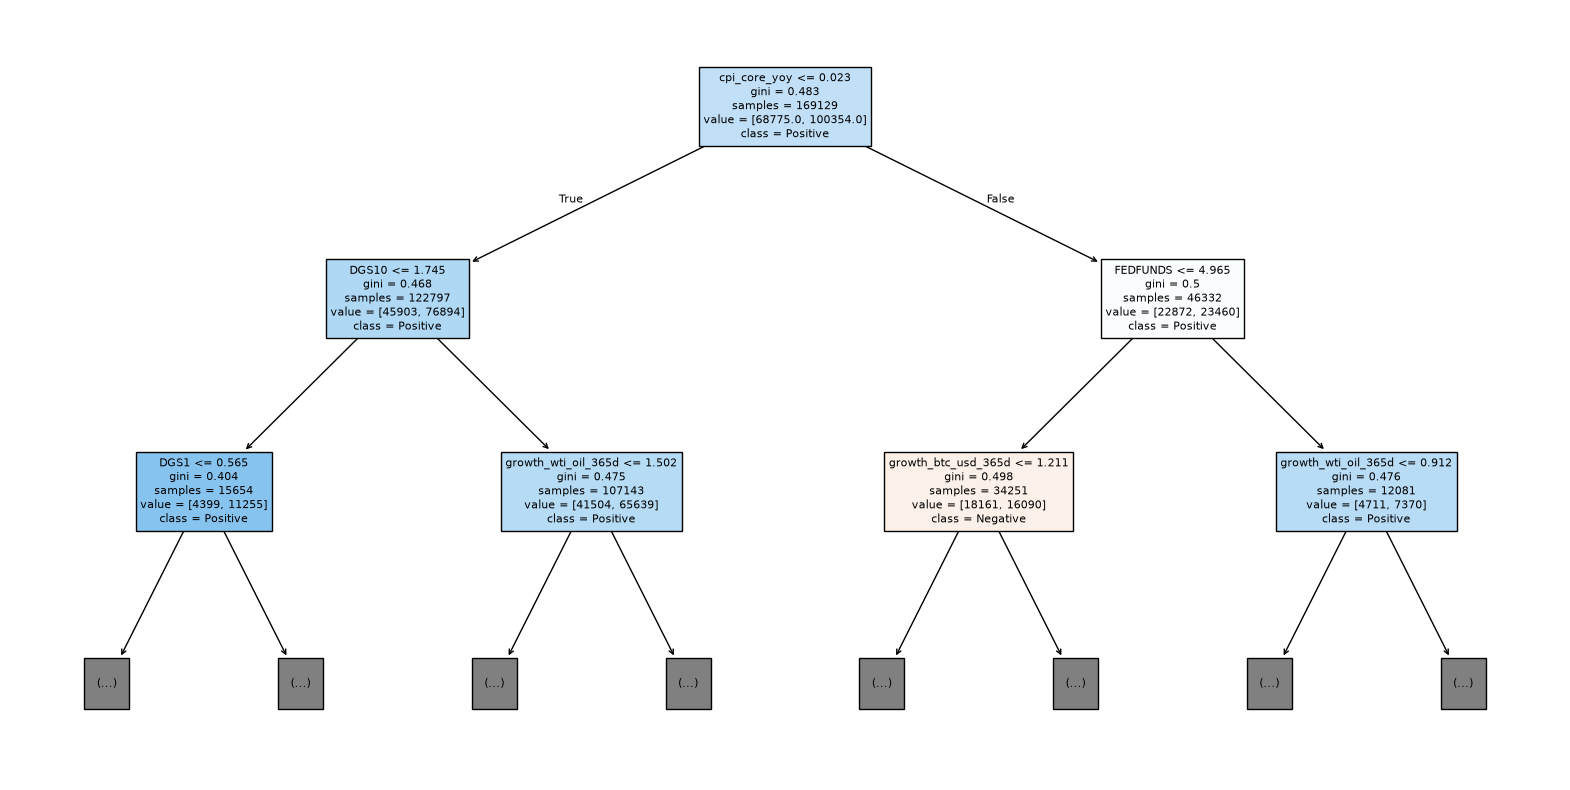

In [136]:
# visualisation: decision tree for a few levels (max_depth variable)
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# figure: 그림 크기. 나무 글자가 겹치지 않게 넓힌다.
plt.figure(figsize=(20,10))  # Set the size of the figure
# plot_tree: 분류 나무를 그린다. filled는 클래스 색, feature_names는 질문 라벨, max_depth=2는 위 두 단계만. 전체를 그리면 읽히지 않아서 2로 자른다.
plot_tree(clf_10,
          filled=True,
          feature_names=train_columns,
          class_names=['Negative', 'Positive'],
          max_depth=2)
plt.show()


In [137]:
# Feautures importance function to predict future returns (based on the classifier)
# get feature importance from 'clf' (classifier) and 'train_columns' (column names)

def get_importances(clf, train_columns):
  # feature_importances_: 피처별 불순도 감소 비율. 어떤 열이 분할에 많이 쓰였는지.
  feature_importance = clf.feature_importances_

  feature_names = train_columns

  feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})

  # sort_values ascending=False: 중요도 큰 순. 상위 피처를 먼저 보게 한다.
  feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

  return feature_importance_df


In [138]:
# head(10): 중요도 상위 10개. 깊이 10 나무가 무엇을 보는지.
get_importances(clf_10, train_columns).head(10)


,Feature,Importance
178,cpi_core_yoy,0.064045
35,growth_gold_365d,0.052179
179,cpi_core_mom,0.046212
41,growth_wti_oil_365d,0.040891
180,FEDFUNDS,0.036570
93,ad,0.035612
95,obv,0.034214
90,trix,0.031728
22,growth_dji_90d,0.031600
53,growth_btc_usd_365d,0.029867


In [139]:
get_importances(clf_20, train_columns).head(10)


,Feature,Importance
95,obv,0.044247
93,ad,0.042071
90,trix,0.034318
5,growth_365d,0.031376
174,volatility,0.026445
178,cpi_core_yoy,0.025202
97,natr,0.022966
35,growth_gold_365d,0.020928
55,adxr,0.020250
4,growth_90d,0.020038


### 1.4.5 Merge with the original df for predictions (only when predicted on test dataset)

In [140]:
# current predictions from MANUAL
PREDICTIONS


['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp']

In [141]:
# head: 앞 5행. 수동 예측 열이 표에 있는지 본다.
new_df.head()


,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,ticker_type_US,split,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,is_correct_pred0,is_correct_pred1,is_correct_pred2,pred_tree_clf10,pred_tree_clf20
0,35.623602,36.002980,33.992277,35.377007,53228400.0,0.0,0.0,MSFT,2000,1,...,1,train,0,1,1,1,0,0,NaN,NaN
1,34.466525,35.547754,34.068178,34.181992,54119000.0,0.0,0.0,MSFT,2000,1,...,1,train,0,1,0,1,0,1,NaN,NaN
2,33.726722,35.320110,33.195592,34.542385,64059600.0,0.0,0.0,MSFT,2000,1,...,1,train,0,1,0,1,0,1,NaN,NaN
3,34.049185,34.561345,32.892081,33.385273,54976600.0,0.0,0.0,MSFT,2000,1,...,1,train,0,1,0,1,0,1,NaN,NaN
4,32.967948,34.068144,32.569601,33.821548,62013600.0,0.0,0.0,MSFT,2000,1,...,1,train,0,1,1,1,0,0,NaN,NaN


In [142]:
# index in df is not unique
# groupby(index): 같은 행 번호가 몇 번인지. count 후 sort. 인덱스가 유일하지 않아 인덱스만으로 못 붙인다는 것을 확인한다.
np.sort(new_df.groupby(new_df.index).split.count())


array([1, 1, 1, ..., 1, 1, 1], shape=(202292,))

In [143]:
# it's hard to join with pred10_df - as index is totally different
pred10_df.head()


,Date,Ticker,pred_tree_clf10
9203,2022-09-16,MSFT,0
9204,2022-09-19,MSFT,1
9205,2022-09-20,MSFT,1
9206,2022-09-21,MSFT,0
9207,2022-09-22,MSFT,1


In [144]:
# TODO 4: JOIN predictions with the original dataframe (define a new column):
#  so, that there are columns pred_tree_clf10 AND pred_tree_clf20
